In [1]:
import os, re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../report/figures", exist_ok=True)
df = pd.read_csv("../data/clean_dataset.csv")
df["length"] = df["text"].str.len()
print(df.shape)
df.head()

(17216, 4)


,text,label,source,length
0,From: lindseydaniels@example.net,email,faker_synthetic,32
1,Sony has long insisted its digital music playe...,safe,ag_news,95
2,On finally.,safe,faker_synthetic,11
3,ign into your account. Your password is 9VPTNu...,credential,ai4privacy,53
4,DB_PASS = 's5KbN3Hg*S7',credential,faker_synthetic,23


In [7]:
%pip install imbalanced-learn xgboost easyocr streamlit opencv-python

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 5.6 MB/s eta 0:00:09
    --------------------------------------- 1.0/48.9 MB 4.6 MB/s eta 0:00:11
    --------------------------------------- 1.0/48.9 MB 4.6 MB/s eta 0:00:11
   - -------------------------------------- 2.1/48.9 MB 2.9 MB/s eta 0:00:17
   -- ------------------------------------- 2.6/48.9 MB 2.8 MB/s eta 0:00:17
   -- ------------------------------------- 2.9/48.9 MB 2.9 MB/s eta 0:00:16
   -- ------------------------------------- 3.1/48.9 MB 2.5 MB/s eta 0:00:19
   -- ------------------------------------- 3.1/48.9 MB 2.5 MB/s eta 0:00:19
   --- ------------------------------------ 3.9/48.9 MB 2.4 MB/s eta 0:00:19
   --- ------------------------------------ 4.5/48.9 MB 2.2 MB/s eta 0:00:21
   ---- ----------------------------------- 5.0/48.9 MB 2.3 MB/s eta 0:00:20
   ---- ----------------------------------- 5.0/48.9 MB 2.3 MB/s eta 0:00:20
   ---


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install matplotlib seaborn scikit-learn

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.3 MB 6.1 MB/s eta 0:00:02
   ------ --------------------------------- 1.6/9.3 MB 4.7 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.3 MB 3.6 MB/s eta 0:00:03
   ---------- ----------------------------- 2.4/9.3 MB 3.1 MB/s eta 0:00:03
   ---------- ----------------------------- 2.4/9.3 MB 3.1 MB/s eta 0:00:03
   ---------- ----------------------------- 2.4/9.3 MB 3.1 MB/s eta 0:00:03
   ---------- ----------------------------- 2.4/9.3 MB 3.1 MB/s eta 0:00:03
   ---------- ----------------------------- 2.4/9.3 MB 3.1 MB/s eta 0:00:03
   ---------- ----------------------------- 2.4/9.3 MB 3.1 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/9.3 MB 1.2 MB/s eta 0:00:06
   ----------- ---------------------------- 2.6/9.3 MB 1.2 MB/s eta 0:00:06
   ------------ --------------------------- 2.9/9.3 MB 1.1 MB/s eta 0:00:06
   ------------ ---


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


label
safe            8756
credential      2700
email           2500
phone           2500
url_internal     760
Name: count, dtype: int64
Imbalance ratio (largest : smallest) = 11.5


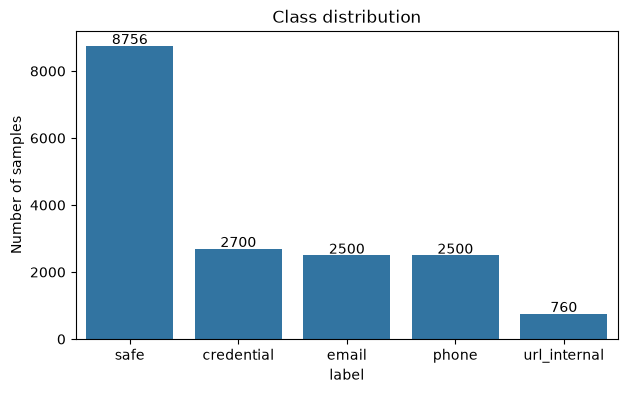

In [2]:
counts = df["label"].value_counts()
print(counts)
print("Imbalance ratio (largest : smallest) =", round(counts.max() / counts.min(), 1))

plt.figure(figsize=(7,4))
sns.barplot(x=counts.index, y=counts.values)
for i, v in enumerate(counts.values):
    plt.text(i, v + 50, str(v), ha="center")
plt.title("Class distribution")
plt.ylabel("Number of samples")
plt.savefig("../report/figures/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

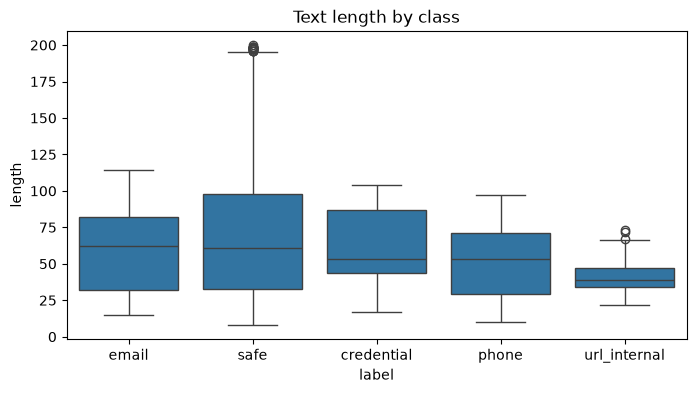

               count  mean   std   min   25%   50%   75%    max
label                                                          
credential    2700.0  60.2  23.6  17.0  44.0  53.0  87.0  104.0
email         2500.0  60.3  27.2  15.0  32.0  62.0  82.0  114.0
phone         2500.0  52.4  24.6  10.0  29.0  53.0  71.2   97.0
safe          8756.0  69.8  43.5   8.0  33.0  60.5  98.0  200.0
url_internal   760.0  40.8   9.0  22.0  34.0  39.0  47.0   73.0
source
ag_news             73.3
ai4privacy          73.6
faker_synthetic     41.0
rotten_tomatoes    107.5
ui_code             19.5
Name: length, dtype: float64


In [3]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df, x="label", y="length")
plt.title("Text length by class")
plt.savefig("../report/figures/length_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby("label")["length"].describe().round(1))
print(df.groupby("source")["length"].mean().round(1))

              digit_ratio  upper_ratio  special_ratio
label                                                
credential          0.086        0.229          0.069
email               0.041        0.036          0.077
phone               0.326        0.032          0.090
safe                0.026        0.033          0.049
url_internal        0.201        0.031          0.199


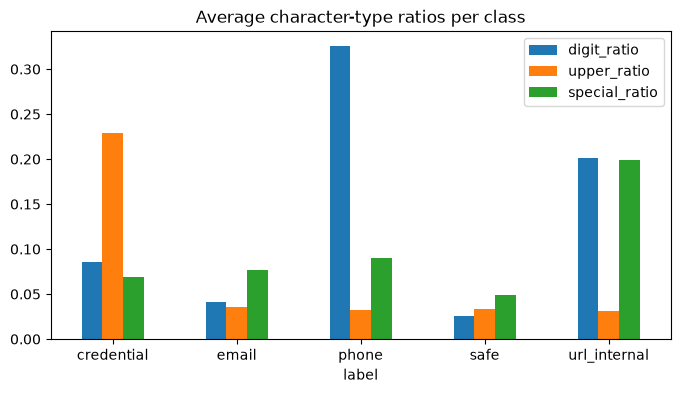

In [5]:
def ratio(pattern):
    return lambda t: len(re.findall(pattern, t)) / max(len(t), 1)

df["digit_ratio"]   = df["text"].apply(ratio(r"\d"))
df["upper_ratio"]   = df["text"].apply(ratio(r"[A-Z]"))
df["special_ratio"] = df["text"].apply(ratio(r"[^A-Za-z0-9\s]"))

feat = df.groupby("label")[["digit_ratio", "upper_ratio", "special_ratio"]].mean().round(3)
print(feat)

feat.plot(kind="bar", figsize=(8,4))
plt.title("Average character-type ratios per class")
plt.xticks(rotation=0)
plt.savefig("../report/figures/char_ratios.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
from sklearn.feature_extraction.text import CountVectorizer

for lab in df["label"].unique():
    cv = CountVectorizer(analyzer="char", ngram_range=(3,4), max_features=2000)
    X = cv.fit_transform(df[df["label"] == lab]["text"])
    freq = pd.Series(X.sum(axis=0).A1, index=cv.get_feature_names_out()).nlargest(8)
    print(lab, "->", list(freq.index))

email -> ['ail', 'mai', 'mail', 'com', '.co', '.com', 'ple', ' to']
safe -> [' th', 'the', 'he ', ' the', 'the ', 'er ', 'ing', 'ng ']
credential -> ['ass', 'pas', 'pass', ' pa', 'ord', 'wor', 'ssw', 'swo']
phone -> [' at', 'at ', ' at ', 'or ', ' co', 'con', ' con', 'act']
url_internal -> ['://', 'htt', 'http', 'ttp', ' ht', ' htt', 'ps:', 'ps:/']


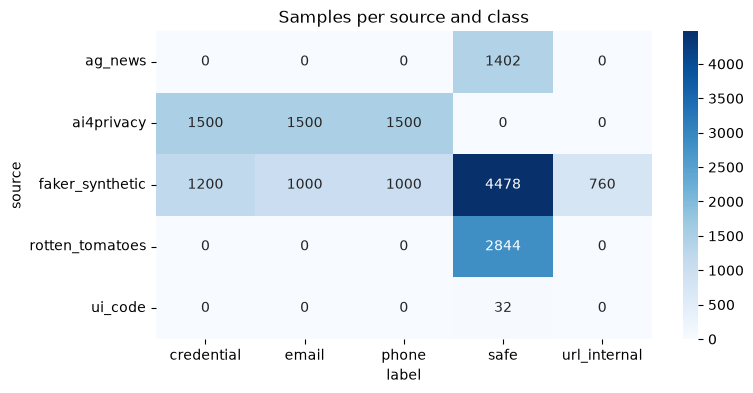

In [7]:
ct = pd.crosstab(df["source"], df["label"])
plt.figure(figsize=(8,4))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Samples per source and class")
plt.savefig("../report/figures/source_label_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
print(df.groupby("label")[["digit_ratio", "upper_ratio", "special_ratio"]].mean().round(3))

              digit_ratio  upper_ratio  special_ratio
label                                                
credential          0.086        0.229          0.069
email               0.041        0.036          0.077
phone               0.326        0.032          0.090
safe                0.026        0.033          0.049
url_internal        0.201        0.031          0.199


## EDA Findings

**1. Class imbalance.**
The cleaned dataset has 17,216 samples across five classes. The safe class is the largest
with 8,756 samples (51%), while url_internal is the smallest with 760 samples (4.4%).
The imbalance ratio is 11.5 to 1. Accuracy alone would be misleading, so we will use class
weights or SMOTE and evaluate with per-class precision, recall and F1 (macro F1).

**2. Character patterns separate the classes.**
Credentials have the highest share of uppercase letters (22.8%, compared with about 3%
for safe text, emails and phones) because they contain random keys and tokens. Phone
numbers have the highest digit share (32.6%), while safe text has the lowest digit
(2.6%) and special-character (4.9%) shares. Internal URLs have the highest
special-character share (19.9%) and a digit share of (20.1%). These differences support using
character n-gram TF-IDF instead of word-level features alone.

**3. Text length differs between classes.**
Safe text is the longest and most variable (mean 69.8 characters, std 43.5, maximum 200).
Emails (60.3), credentials (60.2) and phones (52.4) are similar to each other. Internal
URLs are the shortest (mean 40.8, range 22 to 73). By source, Faker lines average 41.0
characters, while Rotten Tomatoes lines average 107.5. Length alone could leak the label,
so we will check that the models do not rely on it.

**4. Source-style risk and how we reduced it.**
Internal URLs come only from our Faker generator, and the real-style emails, phones and
passwords come only from ai4privacy. A model could learn the style of the source instead
of the true pattern. Our first internal URL generator used only 6 templates, so we
rebuilt it with varied hosts, ports, paths and prefixes, which raised the length variation
(std 7.5 to 9.0) and added mixed-case paths. We will also (a) compare results per source,
(b) compare against a regex baseline, and (c) test on OCR text from our own real
screenshots.

**5. Data quality.**
No missing values were found. 1,565 duplicate rows were removed, mostly repeated Faker
safe lines. Text was limited to 3 to 200 characters to match typical OCR lines, and safe
text containing emails, links or long numbers was filtered out to avoid wrong labels.